# Inference Lab: Pricing Under Uncertainty


**Run this notebook in Google Colab.** The `demand` module is compiled for Linux and Python 3.13 only, so it will not import on a Mac or Windows machine.

The goal of this lab is to use what you've learned in this class to find the optimal price for something. You can't know for sure what the underlying curve of revenue vs price looks like. All you know is what you would know in the real world, information you gain by sampling-- you can market test any price using the demand function below. When you set the price, the market test runs for a certain amount of time, and then reports responses-- a list of 1s (bought) and 0s (didn't buy) for that price point. The total number in the sample, $n$, is therefore a random variable, given by `len(responses)`. The number of consumers who buy the product is `responses.sum().` Every time you run a market test, it takes time (literally, it will take a while to run, so don't do this lab last minute!).

In [1]:
!git clone -q https://github.com/smgroves/demand_lab.git

%cd /content/demand_lab

from demand import demand

responses = demand(price=14.0)

print(len(responses), responses.sum())

/content/demand_lab
184 149


## 1. Compare two prices

Run one market test with price = 30. Then test price = 25. Which price earns more revenue per potential customer?

1. For each price, estimate the proportion $\hat{p}$ of customers who buy, and the revenue per customer $\hat{r}$.
2. Estimate the standard error of each $\hat{r}$ by bootstrapping.
3. Compute a 95% confidence interval for each $\hat{r}$.
4. Compute a 95% confidence interval for the difference $\hat{r}_{25} - \hat{r}_{30}$.
   
5. Interpret the estimates, SEs, and intervals. Report which price earns more profit, and how confident you are.



1.1

In [2]:
from demand import demand

price_A, price_B = 25.0, 30.0
resp_A = demand(price=price_A)
resp_B = demand(price=price_B)

for P, resp in [(price_A, resp_A), (price_B, resp_B)]:
    print(f"${P:g}: n = {len(resp)}, p_hat = {resp.mean():.3f}, r_hat = {P * resp.mean():.2f}")

$25: n = 167, p_hat = 0.359, r_hat = 8.98
$30: n = 187, p_hat = 0.385, r_hat = 11.55


1.2

In [3]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(0)
B = 2000

def bootstrap_r(responses, price, B=B):
    idx = rng.integers(0, len(responses), size=(B, len(responses)))
    return price * responses[idx].mean(axis=1)

def se_formula(responses, price):
    p = responses.mean()
    return price * np.sqrt(p * (1 - p) / len(responses))

reps_A = bootstrap_r(resp_A, price_A)
reps_B = bootstrap_r(resp_B, price_B)

pd.DataFrame([
    {"price": P, "r_hat": P * resp.mean(), "SE (bootstrap)": reps.std(ddof=1), "SE (formula)": se_formula(resp, P)}
    for P, resp, reps in [(price_A, resp_A, reps_A), (price_B, resp_B, reps_B)]
]).round(3)

,price,r_hat,SE (bootstrap),SE (formula)
0,25.0,8.982,0.917,0.928
1,30.0,11.551,1.067,1.068


1.3

In [4]:
def ci_table(pairs):
    rows = []
    for P, resp, reps in pairs:
        r_hat, se = P * resp.mean(), se_formula(resp, P)
        lo_b, hi_b = np.percentile(reps, [2.5, 97.5])
        rows.append({"price": P, "n": len(resp), "r_hat": round(r_hat, 2),
                     "95% CI (bootstrap)": f"({lo_b:.2f}, {hi_b:.2f})",
                     "95% CI (r_hat ± 1.96 SE)": f"({r_hat - 1.96 * se:.2f}, {r_hat + 1.96 * se:.2f})"})
    return pd.DataFrame(rows)

ci_table([(price_A, resp_A, reps_A), (price_B, resp_B, reps_B)])

,price,n,r_hat,95% CI (bootstrap),95% CI (r_hat ± 1.96 SE)
0,25.0,167,8.98,"(7.19, 10.93)","(7.16, 10.80)"
1,30.0,187,11.55,"(9.47, 13.64)","(9.46, 13.64)"


1.4

In [5]:
def diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B):
    d = price_A * resp_A.mean() - price_B * resp_B.mean()
    boot = tuple(np.percentile(reps_A - reps_B, [2.5, 97.5]))
    se = np.sqrt(se_formula(resp_A, price_A) ** 2 + se_formula(resp_B, price_B) ** 2)
    return d, boot, (d - 1.96 * se, d + 1.96 * se)

def verdict(lo, hi, name_A, name_B):
    if lo > 0:
        return f"{name_A} earns more"
    if hi < 0:
        return f"{name_B} earns more"
    return "can't tell (interval contains 0)"

d, boot, z = diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B)
print(f"r_25 - r_30 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$25', '$30')}")
print(f"  95% CI, formula:   ({z[0]:.2f}, {z[1]:.2f})  ->  {verdict(*z, '$25', '$30')}")

r_25 - r_30 = -2.57
  95% CI, bootstrap: (-5.26, 0.20)  ->  can't tell (interval contains 0)
  95% CI, formula:   (-5.34, 0.20)  ->  can't tell (interval contains 0)


1.5

At \$25, 35.9% of 167 customers bought, giving r̂ = \$8.98 per customer (SE ≈ 0.92).

At \$30, 38.5% of 187 customers bought, giving r̂ = \$11.55 per customer (SE ≈ 1.07).

The bootstrap and formula SEs agree closely, and the 95% intervals are about (7.2, 10.9) for \$25 and (9.5, 13.6) for \$30 by bootstrap, with nearly identical formula intervals. Each estimate is fairly imprecise, with an SE of roughly 10% of r̂.

The point estimate favors \$30. The buy rates are similar, so the higher price earns more per customer. The difference r̂_25 − r̂_30 = −2.57, with a 95% CI of (−5.26, 0.20) by bootstrap and (−5.34, 0.20) by formula.

If the whole interval were below 0, that would be evidence that \$30 earns more. If it were all above 0, that would be evidence that \$25 earns more. Here the interval includes 0, so we can't tell which price is better from this data. That does not mean the two prices earn the same. It's possible not enough data was collected to see the difference.

## 2. The cost of sampling

7. Run a second market test at each price. Pool the two price = 30 samples (`np.concatenate`), and pool the two price = 25 samples.
8. Recompute the SEs, the intervals, and the interval for the difference. By roughly what factor did the SE shrink? Explain why, using the SE formula.
   
9.  **Was the extra sampling worth it?** Every market test takes time, and while you're testing you aren't selling at your best price, so each test costs the company revenue. Did the first round already settle the question (its difference interval excluded 0)? If so, the second round cost time and bought nothing but a narrower interval. If not, did the second round settle it?


2.7

In [6]:
from demand import demand

resp_A2 = demand(price=price_A)
resp_B2 = demand(price=price_B)

pool_A = np.concatenate([resp_A, resp_A2])
pool_B = np.concatenate([resp_B, resp_B2])

for P, resp in [(price_A, pool_A), (price_B, pool_B)]:
    print(f"${P:g}: n = {len(resp)}, p_hat = {resp.mean():.3f}, r_hat = {P * resp.mean():.2f}")

$25: n = 357, p_hat = 0.367, r_hat = 9.17
$30: n = 465, p_hat = 0.387, r_hat = 11.61


2.8

In [7]:
pool_reps_A = bootstrap_r(pool_A, price_A)
pool_reps_B = bootstrap_r(pool_B, price_B)

print(f"SE ratio (pooled / one test), bootstrap: ${price_A:g}: {pool_reps_A.std(ddof=1) / reps_A.std(ddof=1):.2f}, "
      f"${price_B:g}: {pool_reps_B.std(ddof=1) / reps_B.std(ddof=1):.2f};  1/sqrt(2) = {1 / np.sqrt(2):.2f}")

d, boot, z = diff_ci(pool_A, price_A, pool_reps_A, pool_B, price_B, pool_reps_B)
print(f"pooled r_25 - r_30 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$25', '$30')}")
print(f"  95% CI, formula:   ({z[0]:.2f}, {z[1]:.2f})  ->  {verdict(*z, '$25', '$30')}")

SE ratio (pooled / one test), bootstrap: $25: 0.69, $30: 0.63;  1/sqrt(2) = 0.71
pooled r_25 - r_30 = -2.44
  95% CI, bootstrap: (-4.32, -0.73)  ->  $30 earns more
  95% CI, formula:   (-4.26, -0.62)  ->  $30 earns more


In [44]:
ci_table([(price_A, pool_A, pool_reps_A), (price_B, pool_B, pool_reps_B)])
print(f"SE (bootstrap): ${price_A:g}: {pool_reps_A.std(ddof=1):.2f}, ${price_B:g}: {pool_reps_B.std(ddof=1):.2f}")

SE (bootstrap): $25: 0.63, $30: 0.68


2.9

The first round did not settle the question. Its difference interval, (−5.26, 0.20), contained 0, so we couldn't tell which price was better.

The second round did settle it. The pooled interval, (−4.32, −0.73), is entirely below 0, which is evidence that \$30 earns more per customer than \$25. The estimated difference is about \$2.44 per customer, and at the 95% level the interval rules out that the two prices earn the same.

The extra sampling was worth it. The first round left us unsure which price was better, but the second made it clear. The cost was the time and lost revenue from running two more tests instead of selling at the better price. That cost bought something here because it changed the decision from "can't tell" to "\$30." If the first round had already excluded 0, the second would have cost time and only narrowed the interval.

## 3. Finding the optimal price

Now find the price that maximizes revenue per customer. Search prices between about \$5 and \$100.

Every market test takes time, and time spent testing is revenue lost: while you test, you aren't selling at your best price. Your confidence intervals tell you whether another test is worth running. **Use as few market tests as you can (<25 would be good).** Your grade will be based on, in this order, whether you:
- accurately used the information you have by accurately interpreting confidence intervals
- found a good price, close to the optimal price
- and used fewer tests.

If this sounds fun to you, run with it! If you are still very confused about what to do, read the hints below.

<details><Summary>Hints</summary>
<b>Hint 1:</b> There are a few ways you could search:

- Brute force: test every price on a fine grid. This takes a market test at every price, including prices that are obviously bad. This would be a bad choice.
- Hill climbing: compare the CI for two prices, move toward the better one, and repeat. For example, start from the 25/30 comparison above; based on which price is better, choose another price \$10 away in that direction (15 if 25 was better; 40 if 30 was better). Shrink the step size as you get close to a good price. If you can't detect a difference between two prices, either shrink the step size or increase the sample size (i.e. run another market test at the same price).
- other strategies that I won't mention here.
  
<b>Hint 2:</b> You may want to try starting your tests with a few different prices across the range; there may be local maxima you will get stuck in if you just hill climb towards a single maximum.

<b>Hint 3:</b> You can make up your own strategy or try a mix of strategies. However, keep in mind that your grade will reflect how well you ran A/B testing and interpreting confidence intervals, more than how complex your strategy is. Similarly, a lucky guess with a brute force strategy would not be a good reproducible strategy.

<b>Hint 4:</b>
Turn your code from part 1 into a function, so you can easily input responses, run bootstrapping, calculate SE, and calculate confidence intervals. Then make another function where you give it two confidence intervals and make a decision based on them: sample more at the same test, or move in one direction with some step size.
   </details>

**Before you run any tests,** write down your plan: which prices you'll test first, how you'll decide where to go next, and what your intervals need to show before you stop. Then follow it, and note anywhere you changed course and why.

For any method, stop when your intervals show that another test is unlikely to change your answer by enough to matter.

**Deliverable:** A ~2-3 paragraph write up of the strategy you chose, your final recommended price, a 95% CI for $r$ at that price, the number of market tests you ran, and one or two sentences on how your intervals told you when to stop.

**Plan before running any tests:**

---
I will first test one price each at \$10, \$50, \$65, \$80, and \$100, in addition to the existing \$25 and \$30 data. I will compare prices using the 95% bootstrap CI for the difference in revenue per customer. If the interval excludes 0, I move toward the better price. If it contains 0, I will run another test at the better-looking price. Once I find the best region, I will move $10 toward the better price and halve the step whenever the direction flips or the interval contains 0. I will stop when the best price beats its neighbors on both sides, or when the largest plausible gain from moving is under about 5% of the best r̂.


**Running tests:**

In [28]:
from demand import demand

data = {25.0: pool_A, 30.0: pool_B}

def test(price):
    data[price] = np.concatenate([data.get(price, []), demand(price=price)])

def summary():
    rows = []
    for P, r in sorted(data.items()):
        reps = bootstrap_r(r, P)
        rows.append({"price": P, "n": len(r), "r_hat": P * r.mean(), "SE": reps.std(ddof=1),
                     "lo": np.percentile(reps, 2.5), "hi": np.percentile(reps, 97.5)})
    return pd.DataFrame(rows).round(2)

def compare(pA, pB):
    lo, hi = np.percentile(bootstrap_r(data[pA], pA) - bootstrap_r(data[pB], pB), [2.5, 97.5])
    print(f"r_{pA:g} - r_{pB:g}: ({lo:.2f}, {hi:.2f}) -> {verdict(lo, hi, f'${pA:g}', f'${pB:g}')}")

In [29]:
# check price range

for P in [10, 50, 65, 80, 100]:
    test(P)
summary()

,price,n,r_hat,SE,lo,hi
0,10.0,163,9.26,0.20,8.83,9.63
1,25.0,357,9.17,0.64,7.84,10.43
2,30.0,465,11.61,0.67,10.39,13.03
3,50.0,144,17.71,1.95,13.89,21.88
4,65.0,257,16.69,1.76,13.40,20.23
5,80.0,151,23.31,2.97,17.48,29.14
6,100.0,159,5.03,1.73,1.89,8.81


In [32]:
#compare $65 with its neighbors
compare(65, 80)
compare(65, 50)
compare(65, 30)

r_65 - r_80: (-13.46, -0.15) -> $80 earns more
r_65 - r_50: (-6.16, 4.10) -> can't tell (interval contains 0)
r_65 - r_30: (1.45, 8.77) -> $65 earns more


In [34]:
# compare 80 with high and low
compare(80, 50)
compare(80, 100)

r_80 - r_50: (-1.23, 12.80) -> can't tell (interval contains 0)
r_80 - r_100: (11.62, 24.74) -> $80 earns more


In [35]:
test(80)
compare(80, 50)
compare(80, 65)

r_80 - r_50: (-2.66, 7.88) -> can't tell (interval contains 0)
r_80 - r_65: (-1.39, 8.93) -> can't tell (interval contains 0)


In [39]:
#check r_hat again after running tests
summary()

,price,n,r_hat,SE,lo,hi
0,10.0,163,9.26,0.20,8.83,9.63
1,25.0,357,9.17,0.64,7.98,10.43
2,30.0,465,11.61,0.68,10.32,12.97
3,50.0,144,17.71,2.03,13.89,21.88
4,65.0,257,16.69,1.76,13.40,20.23
5,80.0,332,20.48,1.89,16.87,24.10
6,100.0,159,5.03,1.72,1.89,8.81


In [40]:
test(80)
compare(80, 50)
compare(80, 65)

r_80 - r_50: (-3.02, 6.56) -> can't tell (interval contains 0)
r_80 - r_65: (-1.78, 7.09) -> can't tell (interval contains 0)


In [41]:
compare(80, 50)
compare(80, 65)
compare(80, 100)

r_80 - r_50: (-3.02, 6.56) -> can't tell (interval contains 0)
r_80 - r_65: (-1.68, 7.11) -> can't tell (interval contains 0)
r_80 - r_100: (9.77, 18.69) -> $80 earns more


In [42]:
summary()

,price,n,r_hat,SE,lo,hi
0,10.0,163,9.26,0.21,8.83,9.63
1,25.0,357,9.17,0.63,7.98,10.36
2,30.0,465,11.61,0.70,10.26,13.03
3,50.0,144,17.71,2.02,13.88,21.53
4,65.0,257,16.69,1.75,13.15,19.98
5,80.0,577,19.41,1.39,16.78,22.19
6,100.0,159,5.03,1.74,1.89,8.81


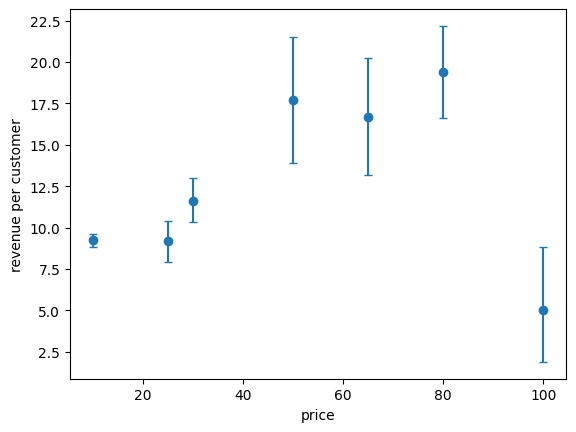

In [43]:
import matplotlib.pyplot as plt

s = summary()
plt.errorbar(s.price, s.r_hat, yerr=[s.r_hat - s.lo, s.hi - s.r_hat], fmt="o", capsize=3)
plt.xlabel("price")
plt.ylabel("revenue per customer")
plt.show()

**Changes made to my plan:**

---

-  \$80 vs \$50 and \$80 vs \$65 both contained 0, so I followed my plan and tested the better-looking price again. A second test still left both intervals containing 0, and I stopped there.
- My plan was originally to move in \$10 steps and halve the step. Testing showed a broad region of high revenue from about \$50 to \$80 that the intervals couldn't separate, so smaller increments wouldn't have told the prices apart.
- The gain from moving was still several dollars, well above 5% of r̂. Getting under that would have taken many times more data, so I stopped because more tests cost more than they could realistically gain

A ~2-3 paragraph write up of the strategy you chose, your final recommended price, a 95% CI for  r  at that price, the number of market tests you ran, and one or two sentences on how your intervals told you when to stop.

**write up:**

---
I started with one market test each at &#36;10, &#36;50, &#36;65, &#36;80, and &#36;100, alongside my pooled &#36;25 and &#36;30 data, to look for the high-revenue region across the whole range. I then compared prices using the 95% bootstrap interval for the difference in revenue per customer, and followed my plan: if an interval excluded 0, I dropped the worse price, and if it contained 0, I resampled the better-looking price instead of assuming the prices were equal. The sweep ruled out the extremes. &#36;65 beat &#36;30, with an interval of (1.45, 8.77), and &#36;80 beat &#36;100, with an interval of (11.62, 24.74). I chose prices spread across the &#36;5 to &#36;100 range so that I would not miss a second peak, and &#36;10 and &#36;25 came back low (about &#36;9 per customer each), far below the &#36;50 to &#36;80 region. The estimates at &#36;50, &#36;65, and &#36;80 were close, so I tested &#36;80 twice more because it had the highest estimate. I did not hill climb in smaller steps, because the intervals could not separate the prices in that region.

My recommended price is &#36;80, with an estimated revenue per customer of &#36;19.41 and a 95% CI of (16.78, 22.19), based on 577 customers. &#36;80 had the highest estimate, but the data cannot separate it from its neighbors: &#36;80 vs &#36;50 gave (-3.02, 6.56) and &#36;80 vs &#36;65 gave (−1.68, 7.11) both contain 0. That does not mean the prices earn the same, only that my samples were too small to see a difference. The true best price could be anywhere from about &#36;50 to &#36;80. The estimate at &#36;80 also fell from 23.31 to 19.41 as its sample grew.

I ran 7 market tests for question 3, but if we include questions 1 and 2, an additional 4 test were ran, for a grand total of 11 market tests. I stopped because my intervals showed that more tests were unlikely to be worth their cost. My initial plan/rule was to stop when the gain from moving was under about 5% of the best estimate. The intervals still allowed gains of several dollars, so the plan needed to be altered. Shrinking them to &#36;1 would have taken many times more data than my budget allowed, so I stopped. Overall, I am reporting a plateau in price around &#36;50 to &#36;80 with &#36;80 as my best estimate.
